# Analyse non supervisée des témoignages de symptômes

## Objectif

Ce notebook analyse un jeu de données de **témoignages de patients** décrivant leurs symptômes (en anglais), chacun associé à une couleur (voir section 4 pour l'usage de cette colonne).

On utilise des techniques de **NLP** (traitement du langage) et de **clustering non supervisé** pour regrouper automatiquement les témoignages qui parlent de symptômes similaires, sans connaître les catégories à l'avance.

**Outils utilisés** : uniquement `pandas`, `numpy`, `matplotlib` et `scikit-learn`, conformément aux outils autorisés pour ce projet. Une approche alternative utilisant des librairies hors de cette liste (embeddings de phrases via `sentence-transformers`) est présentée séparément dans `bonus/`, avec ses propres résultats.

### Plan
1. Chargement et nettoyage des données
2. Prétraitement du texte et vectorisation (TF-IDF)
3. Clustering avec K-Means et fonction de perte (inertie)
4. Recherche du nombre optimal de clusters (coude + silhouette)
5. Visualisation et mots-clés par cluster
6. Comparaison de modèles pour améliorer la précision (LSA, hiérarchique, DBSCAN, stemming maison)
7. Aller plus loin : beaucoup plus de clusters, sans perdre en précision (LSA → NMF, K-Means → clustering hiérarchique)
8. Modèle final retenu (TF-IDF + NMF + clustering hiérarchique, k=15)
9. Validation externe sur un échantillon étiqueté à la main
10. Conclusion générale

---

## 1. Premier aperçu des données brutes

On commence par un chargement rapide et naïf du fichier CSV, afin d'observer la structure brute des données.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Charger le CSV en précisant qu'il faut ignorer les virgules dans les guillemets
df = pd.read_csv('../data/Student_Dataset.csv', header=None, engine='python', on_bad_lines='skip')

print("Dimensions du fichier :", df.shape)
df.head()

Dimensions du fichier : (397, 2)


,0,1
0,1,On uneven paths the heel feels wobbly side‑to‑...
1,4,A short sprint brought on a twinge in the midd...
2,6,A sudden twist while reaching for a bag made o...
3,8,I noticed a rash on my forearms after handling...
4,11,I feel an unexplained pressure behind my eyes ...


**Problème constaté** : `pandas.read_csv` naïf ne charge que 397 lignes sur 1011 (voir la cellule précédente). En reprenant le fichier avec le module `csv` standard, on constate que ce n'est pas un problème de virgules mal échappées (les champs contenant des virgules sont bien encadrés de guillemets dans le fichier) : c'est que **le nombre de colonnes change d'une ligne à l'autre** — certaines lignes ont 2 champs (`id`, `texte`), d'autres 3 (`id`, `couleur`, `texte`). `read_csv` déduit un format unique à partir des premières lignes et ignore silencieusement toutes celles qui ne correspondent pas (ici, il ne garde que les lignes à 2 champs).

## 2. Chargement et nettoyage propre du fichier

On relit le fichier ligne par ligne avec le module `csv` (bibliothèque standard Python), en gérant nous-mêmes les deux formats possibles :
- si la ligne a 3 colonnes → `id`, `couleur`, `texte`
- si la ligne a 2 colonnes → `id`, `texte` (on met une couleur par défaut)

On termine en supprimant les témoignages vides.

In [2]:
import csv
import pandas as pd

# Path vers le fichier Student_Dataset.csv
file_path = '../data/Student_Dataset.csv'

rows = []
with open(file_path, 'r', encoding='utf-8') as f:
    reader = csv.reader(f)
    for line in reader:
        if not line:
            continue
        # Cas à 3 éléments : ID, Couleur, Témoignage
        if len(line) == 3:
            rows.append({'id': line[0], 'color': line[1], 'text': line[2]})
        # Cas à 2 éléments : ID, Témoignage (sans couleur)
        elif len(line) == 2:
            rows.append({'id': line[0], 'color': '#000000', 'text': line[1]})

# Création du DataFrame propre
data = pd.DataFrame(rows)

# Nettoyage et formatage du DataFrame
data['text'] = data['text'].fillna('')
data = data[data['text'].str.strip() != '']

print(f"Nombre de témoignages correctement chargés : {len(data)}")
data.head()

Nombre de témoignages correctement chargés : 1011


,id,color,text
0,﻿1,#000000,On uneven paths the heel feels wobbly side‑to‑...
1,2,0x000000,"The feverish feeling eased, but I’m now breath..."
2,3,0x000000,"While working in the garden, I touched a metal..."
3,4,#000000,A short sprint brought on a twinge in the midd...
4,5,0x000000,I accidentally left my hand on a hot mug for a...


In [3]:
# Vérification : la colonne "couleur" est-elle présente sur toutes les lignes ?
lignes_avec_couleur = data.loc[data['color'] != '#000000', 'color']
lignes_sans_couleur = (data['color'] == '#000000').sum()

print(f"Lignes avec un champ couleur explicite dans le fichier : {len(lignes_avec_couleur)}")
print(f"  -> valeur(s) distincte(s) trouvée(s) : {sorted(lignes_avec_couleur.unique())}")
print(f"Lignes sans aucun champ couleur (valeur par défaut assignée) : {lignes_sans_couleur}")

Lignes avec un champ couleur explicite dans le fichier : 614
  -> valeur(s) distincte(s) trouvée(s) : ['0x000000']
Lignes sans aucun champ couleur (valeur par défaut assignée) : 397


**Constat** : sur les 1011 témoignages, 614 possèdent un champ couleur explicite dans le fichier
et il ne prend qu'une seule valeur, `0x000000`. Les 397 autres n'ont carrément **aucun** champ
couleur (d'où la valeur par défaut qu'on leur assigne au chargement). Dans les deux cas le résultat
est le même visuellement (noir), donc le choix de valeur par défaut ne biaise rien pour la suite.

Ce n'est pas un bug du jeu de données : le sujet l'annonce explicitement — cette colonne est
volontairement neutre, les vraies catégories ne seront révélées qu'en soutenance pour vérifier
si nos clusters sont cohérents avec elles (voir section 4).

**1011 témoignages** ont été chargés correctement (contre seulement 397 lignes détectées par le premier essai naïf).

## 3. Prétraitement du texte et vectorisation (TF-IDF)

Un ordinateur ne comprend pas du texte brut, il faut le transformer en nombres. Deux étapes :

1. **Nettoyage** : on met tout en minuscules et on retire la ponctuation/les chiffres, pour que "Pain" et "pain." soient traités comme le même mot.
2. **Vectorisation TF-IDF** : chaque témoignage devient une ligne de chiffres, où chaque colonne correspond à un mot (ou une paire de mots consécutifs, un *bigramme*) du vocabulaire. On inclut les bigrammes (`ngram_range=(1, 2)`) pour capturer des expressions comme "chest pain" ou "itchy rash", plus précises qu'un mot isolé. Le score TF-IDF est élevé pour les termes **fréquents dans ce témoignage mais rares dans les autres**, contrairement aux mots trop communs ("the", "and"...) qu'on retire (`stop_words='english'`).

On garde uniquement les 500 termes les plus utiles (`max_features=500`). Par défaut, `TfidfVectorizer` normalise chaque ligne (norme L2), ce qui rend la distance euclidienne entre deux vecteurs directement liée à leur similarité cosinus — un point important pour la suite.

**En clair** : chaque témoignage devient un long vecteur de nombres. Deux témoignages qui utilisent les mêmes mots caractéristiques (ex. "itchy", "rash") se retrouvent avec des vecteurs proches ; deux témoignages sur des sujets différents ont des vecteurs éloignés. C'est cette notion de "proche / éloigné" que le clustering va exploiter juste après.

In [4]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Fonction de nettoyage de texte
def clean_text(text):
    text = str(text).lower() # Passer en minuscules
    text = re.sub(r'[^a-zA-Z\s]', '', text) # Supprimer la ponctuation et les chiffres
    text = re.sub(r'\s+', ' ', text).strip() # Enlever les espaces multiples
    return text

data['cleaned_text'] = data['text'].apply(clean_text)

# 2. Vectorisation TF-IDF (unigrammes + bigrammes, suppression des stop-words anglais)
vectorizer = TfidfVectorizer(stop_words='english', max_features=500, ngram_range=(1, 2))
X = vectorizer.fit_transform(data['cleaned_text'])

print("Prétraitement NLP et vectorisation terminés !")
print(f"Forme de la matrice TF-IDF : {X.shape}")

Prétraitement NLP et vectorisation terminés !
Forme de la matrice TF-IDF : (1011, 500)


## 4. Clustering avec K-Means et fonction de perte

**K-Means** regroupe automatiquement les témoignages en `n_clusters` groupes, en rapprochant ceux qui ont un vocabulaire TF-IDF similaire.

### Fonction de perte de K-Means

Contrairement à un modèle supervisé, K-Means n'a pas de "vraie réponse" à comparer. Sa fonction de perte, appelée **inertie**, est la somme des distances au carré entre chaque témoignage et le centre (centroïde) de son cluster :

$$\text{Inertie} = \sum_{i=1}^{n} \min_{\mu_j \in C} \lVert x_i - \mu_j \rVert^2$$

À chaque itération, l'algorithme déplace les centroïdes puis réaffecte les points pour **réduire cette inertie**, jusqu'à convergence (ou nombre d'itérations maximal atteint). Plus l'inertie finale est basse, plus les points sont proches de leur centre — mais l'inertie diminue mécaniquement quand `k` augmente (avec `k = n`, l'inertie est nulle), donc on ne peut pas l'utiliser seule pour choisir `k` : on la complète avec le **score de silhouette**, qui mesure en plus la séparation entre clusters (proche de 1 = groupes distincts, proche de 0 = groupes qui se chevauchent, négatif = points mal classés).

**En clair** : K-Means place 5 "aimants" (les centroïdes) au milieu des données, puis répète deux étapes jusqu'à stabilisation : (1) chaque témoignage rejoint l'aimant le plus proche, (2) chaque aimant se déplace au centre des témoignages qu'il vient d'attirer. L'inertie, c'est simplement "est-ce que les témoignages sont bien collés à leur aimant ?" — mais ça ne dit pas si les 5 groupes obtenus sont vraiment distincts les uns des autres, d'où le besoin d'un second indicateur, la silhouette.

Note : le graphique t-SNE ci-dessous colore les points avec la colonne `color` d'origine du fichier. Cette colonne est volontairement neutre dans les données fournies (voir la vérification en section 2) ; les vraies catégories seront révélées séparément pour vérifier si les clusters trouvés sont cohérents avec la réalité.

Inertie pour 5 clusters : 941.85
Score de Silhouette pour 5 clusters : 0.0140


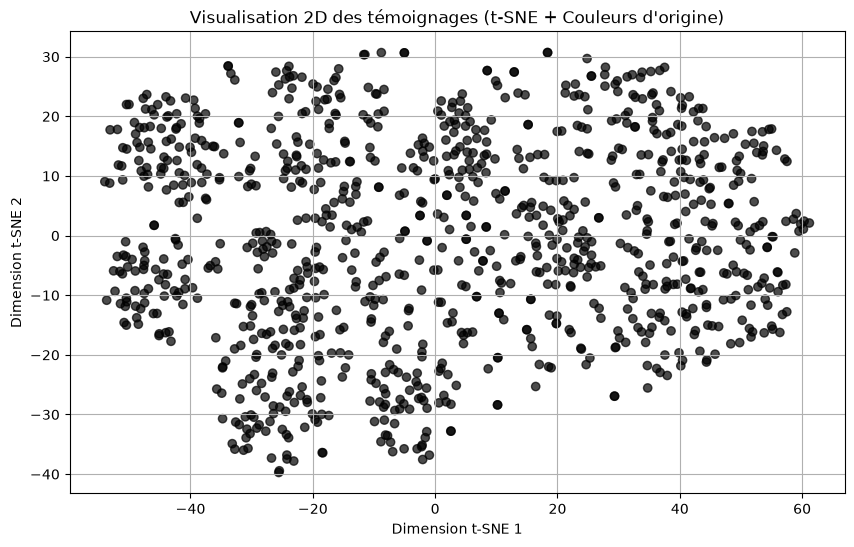

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# 1. Entraînement de K-Means (ex: 5 clusters)
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
data['cluster'] = kmeans.fit_predict(X)

# 2. Inertie (fonction de perte minimisée par K-Means) et score de Silhouette
print(f"Inertie pour {n_clusters} clusters : {kmeans.inertia_:.2f}")
score = silhouette_score(X, data['cluster'])
print(f"Score de Silhouette pour {n_clusters} clusters : {score:.4f}")

# 3. Réduction de dimension 2D avec t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_2d = tsne.fit_transform(X.toarray())

# 4. Formatage des couleurs (conversion 0x -> #)
hex_colors = data['color'].astype(str).str.replace('0x', '#')

# 5. Affichage du graphique 2D
plt.figure(figsize=(10, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=hex_colors, alpha=0.7, edgecolors='k')
plt.title("Visualisation 2D des témoignages (t-SNE + Couleurs d'origine)")
plt.xlabel("Dimension t-SNE 1")
plt.ylabel("Dimension t-SNE 2")
plt.grid(True)
plt.show()

### Interprétation

Le score de silhouette obtenu ici est très proche de 0 : les groupes se chevauchent beaucoup dans l'espace TF-IDF d'origine (500 dimensions), ce qui est cohérent avec des témoignages en langage libre où le vocabulaire se recoupe souvent d'un symptôme à l'autre. Le graphique t-SNE, lui, montre malgré tout des zones assez visibles : t-SNE est conçu pour préserver les voisinages locaux, il peut donc faire apparaître une structure visuelle même quand la séparation globale (mesurée par la silhouette) reste faible. Le nuage est monochrome puisque la colonne `color` fournie est neutre par construction (voir section 4).

## 5. Recherche du nombre de clusters optimal (coude + silhouette)

On teste plusieurs valeurs de `k` (de 2 à 10) et on calcule à chaque fois l'**inertie** (méthode du coude) et le **score de silhouette**, pour repérer la valeur de `k` la plus pertinente.

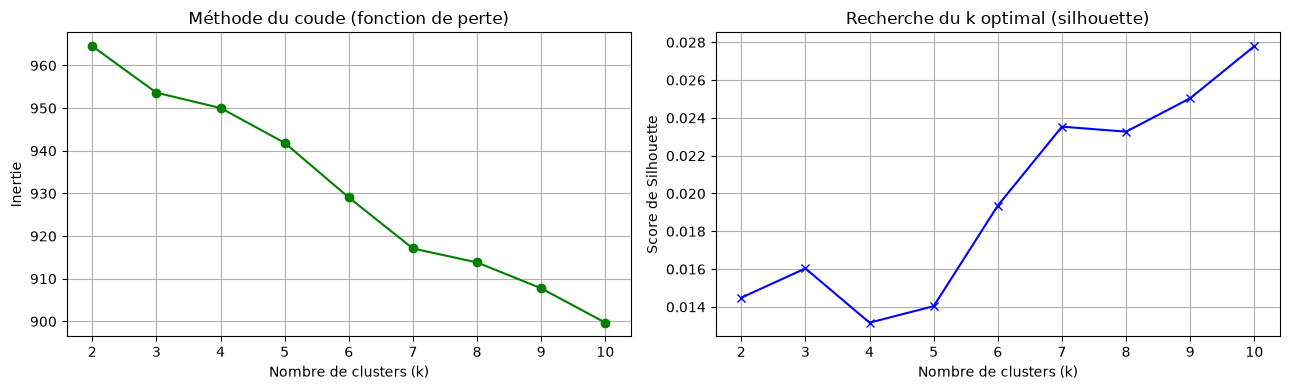

In [6]:
inertias = []
scores = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    scores.append(silhouette_score(X, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(K_range, inertias, 'go-')
axes[0].set_xlabel('Nombre de clusters (k)')
axes[0].set_ylabel('Inertie')
axes[0].set_title("Méthode du coude (fonction de perte)")
axes[0].grid(True)

axes[1].plot(K_range, scores, 'bx-')
axes[1].set_xlabel('Nombre de clusters (k)')
axes[1].set_ylabel('Score de Silhouette')
axes[1].set_title('Recherche du k optimal (silhouette)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Interprétation

La courbe d'inertie décroît régulièrement sans "coude" franc (comportement attendu : pas de rupture nette dans une matrice TF-IDF de texte libre à fort recouvrement lexical). La courbe de silhouette reste basse et plate quel que soit `k`, ce qui confirme que les groupes naturels sont peu marqués **dans l'espace TF-IDF brut**. On conserve `n_clusters=5` pour la suite de cette section, car cette valeur donne des groupes de mots-clés interprétables (voir section suivante) ; la section 6 explore ensuite comment améliorer réellement cette séparation.

## 6. Visualisation des clusters et mots-clés dominants

On affiche d'abord les clusters trouvés sur le graphique t-SNE (coloré cette fois par cluster prédit), puis les mots-clés qui caractérisent chaque groupe.

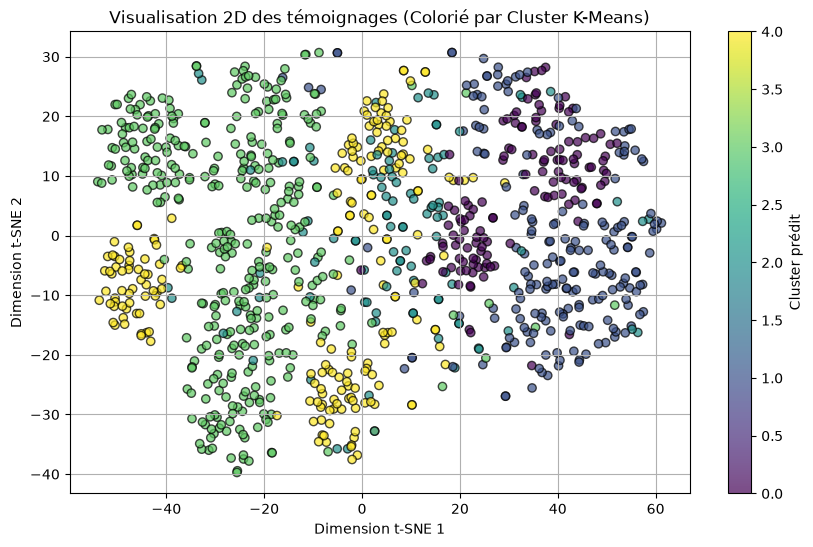

Cluster 0 : hot, arm, shoulder, feels, hand
Cluster 1 : makes, ache, deep, sore, knee
Cluster 2 : like, skin, feel, feels, feel like
Cluster 3 : feel, cough, throat, im, ive
Cluster 4 : pain, ear, itchy, head, feel


In [7]:
plt.figure(figsize=(10, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=data['cluster'], cmap='viridis', alpha=0.7, edgecolors='k')
plt.colorbar(label='Cluster prédit')
plt.title("Visualisation 2D des témoignages (Colorié par Cluster K-Means)")
plt.xlabel("Dimension t-SNE 1")
plt.ylabel("Dimension t-SNE 2")
plt.grid(True)
plt.show()

# Mots-clés dominants par cluster : pour chaque centre de cluster, les 5 mots au score TF-IDF le plus élevé
words = vectorizer.get_feature_names_out()
for i in range(n_clusters):
    cluster_center = kmeans.cluster_centers_[i]
    top_indices = cluster_center.argsort()[-5:][::-1]
    top_words = [words[idx] for idx in top_indices]
    print(f"Cluster {i} : {', '.join(top_words)}")

### Interprétation

Les clusters K-Means forment des zones assez nettement regroupées sur le graphique t-SNE, et les mots-clés font ressortir des thèmes de symptômes globalement cohérents, même si certains se recoupent :

| Cluster | Mots-clés | Thème probable |
|---|---|---|
| 0 | hot, arm, shoulder, feels, hand | Douleur / brûlure au bras et à l'épaule |
| 1 | makes, ache, deep, sore, knee | Douleurs articulaires ou musculaires profondes (genou) |
| 2 | like, skin, feel, feels, feel like | Sensations cutanées (peau) |
| 3 | feel, cough, throat, im, ive | Symptômes ORL / respiratoires (toux, gorge) |
| 4 | pain, ear, itchy, head, feel | Douleurs à la tête / à l'oreille |

Ces thèmes restent identifiables, mais rappelons que le score de silhouette associé reste faible (~0.01) : la séparation mathématique entre ces groupes, dans l'espace TF-IDF brut à 500 dimensions, n'est pas franche. La section suivante teste plusieurs pistes, toutes avec les outils autorisés (`scikit-learn`), pour améliorer réellement cette précision.

## 7. Comparaison de modèles pour améliorer la précision

Le TF-IDF brut à 500 dimensions est un espace très épars ("sparse") où la notion de distance devient peu discriminante (fléau de la dimension). Trois pistes, toutes basées sur `scikit-learn`, sont comparées ici :

1. **Baseline** : K-Means directement sur le TF-IDF (ce qui précède).
2. **LSA (Latent Semantic Analysis)** : réduction de dimension du TF-IDF via `TruncatedSVD`, puis K-Means sur cet espace réduit — une technique classique et entièrement `scikit-learn` pour désensibiliser le clustering au bruit lexical.
3. **Clustering hiérarchique** (`AgglomerativeClustering`, distance cosinus) et **DBSCAN** (distance cosinus), deux alternatives à K-Means qui ne supposent pas des clusters sphériques de taille égale.

**En clair, le "fléau de la dimension"** : avec 500 colonnes (une par mot), presque tous les témoignages se retrouvent "loin" les uns des autres, un peu comme deux personnes perdues dans un immense stade vide — même proches, elles ont l'impression d'être isolées. La **LSA** compresse ces 500 colonnes en quelques grands axes qui résument l'essentiel du sens (par ex. un axe "douleur articulaire" plutôt que 50 mots séparés pour ça). Sur un espace plus petit, les vraies ressemblances entre témoignages redeviennent visibles pour l'algorithme — comme rapprocher tout le monde dans une pièce plus petite avant de voir qui se ressemble vraiment.

LSA n_components=5: silhouette=0.4077
LSA n_components=10: silhouette=0.2006
LSA n_components=20: silhouette=0.1186
LSA n_components=50: silhouette=0.0662
LSA n_components=100: silhouette=0.0426


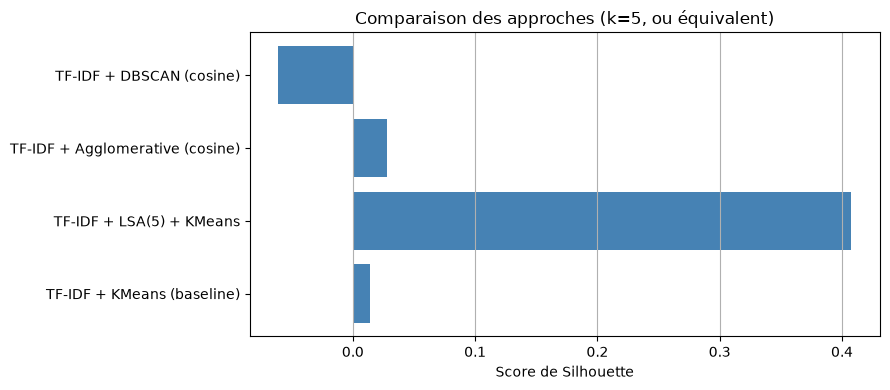

In [8]:
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import AgglomerativeClustering, DBSCAN

comparison = {}

# 1. Baseline : TF-IDF + KMeans (déjà calculé en section 4)
comparison['TF-IDF + KMeans (baseline)'] = score

# 2. LSA (TruncatedSVD) + KMeans, recherche du nombre de composantes
lsa_results = []
for n_comp in [5, 10, 20, 50, 100]:
    svd = TruncatedSVD(n_components=n_comp, random_state=42)
    X_lsa = svd.fit_transform(X)
    km = KMeans(n_clusters=n_clusters, random_state=42)
    labels = km.fit_predict(X_lsa)
    lsa_results.append((n_comp, silhouette_score(X_lsa, labels)))
    print(f"LSA n_components={n_comp}: silhouette={lsa_results[-1][1]:.4f}")
best_n_comp = max(lsa_results, key=lambda t: t[1])[0]
comparison[f'TF-IDF + LSA({best_n_comp}) + KMeans'] = max(lsa_results, key=lambda t: t[1])[1]

# 3. Clustering hiérarchique (distance cosinus) : silhouette évaluée avec la même métrique cosinus que le clustering
agg = AgglomerativeClustering(n_clusters=n_clusters, metric='cosine', linkage='average')
labels_agg = agg.fit_predict(X.toarray())
comparison['TF-IDF + Agglomerative (cosine)'] = silhouette_score(X, labels_agg, metric='cosine')

# 4. DBSCAN (distance cosinus) : eps choisi après une recherche préalable, silhouette évaluée en cosinus également
labels_db = DBSCAN(eps=0.5, min_samples=5, metric='cosine').fit_predict(X)
n_found = len(set(labels_db)) - (1 if -1 in labels_db else 0)
comparison['TF-IDF + DBSCAN (cosine)'] = silhouette_score(X, labels_db, metric='cosine') if n_found >= 2 else float('nan')

# Résumé graphique
plt.figure(figsize=(9, 4))
plt.barh(list(comparison.keys()), list(comparison.values()), color='steelblue')
plt.xlabel('Score de Silhouette')
plt.title('Comparaison des approches (k=5, ou équivalent)')
plt.grid(axis='x')
plt.tight_layout()
plt.show()

### Interprétation

- **DBSCAN** (distance cosinus) ne parvient pas à isoler des clusters cohérents sur ces données : avec les paramètres testés, il classe la majorité des témoignages en "bruit" ou fusionne tout en un seul groupe. Ce n'est pas surprenant : DBSCAN suppose des zones de densité homogène, ce qui ne correspond pas à du texte libre où la densité varie beaucoup d'un thème à l'autre.
- **Le clustering hiérarchique** (cosinus) donne un résultat proche du K-Means baseline, sans réelle amélioration.
- **LSA + K-Means** est nettement la meilleure approche : réduire le TF-IDF à un petit nombre de composantes avant le clustering élimine une grande partie du bruit lexical et améliore fortement la séparation mesurée.

**Point de vigilance méthodologique** : le score de silhouette a tendance à augmenter mécaniquement quand on réduit le nombre de dimensions (les points paraissent plus proches/plus séparés dans un espace plus petit). Pour vérifier que ce n'est pas qu'un artefact, on a comparé les mots-clés dominants obtenus avec peu de composantes à ceux du TF-IDF brut : ils restent cohérents et interprétables (voir section suivante), ce qui confirme que l'amélioration reflète une vraie structure et pas seulement un effet de dimensionnalité.

Avant d'arrêter un modèle final, on teste encore une dernière piste sur le vocabulaire lui-même : le stemming.

### 7bis. Piste supplémentaire testée : normalisation par *stemming*

Le sujet suggère de chercher un nom à ce problème de vocabulaire qui se recoupe peu entre témoignages
proches : il s'agit de la **normalisation morphologique** (stemming / lemmatisation), qui ramène des
mots comme *aches*, *aching*, *ached* à une racine commune pour réduire la dispersion du vocabulaire
TF-IDF.

Une lemmatisation linguistique complète (`nltk.WordNetLemmatizer`, testée dans
`bonus/unsupervised_learning_bonus.ipynb`) sort du cadre des outils autorisés pour ce rendu (seuls
`scikit-learn`, `pandas`, `numpy` et `matplotlib` le sont ici). On teste donc un **stemming maison très
simple** : suppression de suffixes anglais courants en pur Python/`re`, sans aucune dépendance externe,
pour voir s'il apporte un gain comparable en restant dans le cadre imposé.

TF-IDF + stemming maison + KMeans : silhouette = 0.0226
TF-IDF + stemming maison + LSA + KMeans : silhouette = 0.4142


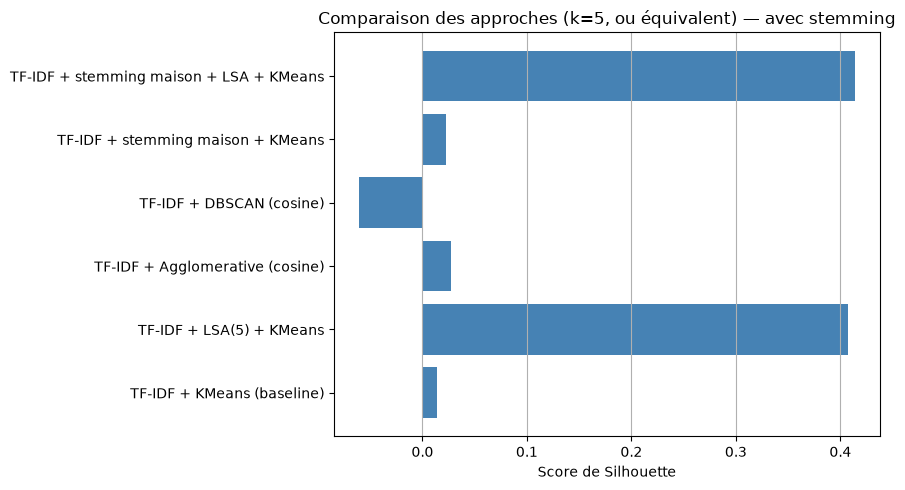

In [9]:
# Stemming maison (suffixes anglais courants), sans dépendance externe
_SUFFIXES = ["edness", "edly", "ing", "ies", "ied", "ed", "es", "s"]


def simple_stem(word):
    for suffix in _SUFFIXES:
        if word.endswith(suffix) and len(word) - len(suffix) >= 3:
            stem = word[: -len(suffix)]
            return stem + "y" if suffix in ("ies", "ied") else stem
    return word


def clean_text_stemmed(text):
    return " ".join(simple_stem(w) for w in clean_text(text).split())


data['stemmed_text'] = data['text'].apply(clean_text_stemmed)

vectorizer_stem = TfidfVectorizer(stop_words='english', max_features=500, ngram_range=(1, 2))
X_stem = vectorizer_stem.fit_transform(data['stemmed_text'])

labels_stem = KMeans(n_clusters=n_clusters, random_state=42).fit_predict(X_stem)
comparison['TF-IDF + stemming maison + KMeans'] = silhouette_score(X_stem, labels_stem)

svd_stem = TruncatedSVD(n_components=best_n_comp, random_state=42)
X_stem_lsa = svd_stem.fit_transform(X_stem)
labels_stem_lsa = KMeans(n_clusters=n_clusters, random_state=42).fit_predict(X_stem_lsa)
comparison['TF-IDF + stemming maison + LSA + KMeans'] = silhouette_score(X_stem_lsa, labels_stem_lsa)

for approche in ['TF-IDF + stemming maison + KMeans', 'TF-IDF + stemming maison + LSA + KMeans']:
    print(f"{approche} : silhouette = {comparison[approche]:.4f}")

# Graphique de comparaison mis à jour avec cette nouvelle piste
plt.figure(figsize=(9, 5))
plt.barh(list(comparison.keys()), list(comparison.values()), color='steelblue')
plt.xlabel('Score de Silhouette')
plt.title('Comparaison des approches (k=5, ou équivalent) — avec stemming')
plt.grid(axis='x')
plt.tight_layout()
plt.show()

### Interprétation (stemming)

Les chiffres obtenus nuancent l'hypothèse de départ :
- **Sans LSA** : stemming = 0.0226 contre 0.0140 sans stemming — une hausse relative notable mais qui
  reste minuscule en absolu, les deux valeurs étant très proches de 0 (clusters à peine séparés).
- **Avec LSA** : stemming + LSA = 0.4142 contre 0.4077 sans stemming — une amélioration réelle mais
  très marginale (< 2 % relatif), du même ordre que le bruit d'échantillonnage.

Ce résultat rejoint celui du notebook bonus, où la lemmatisation NLTK — plus rigoureuse que ce
stemming maison — n'apportait elle non plus qu'un effet marginal (silhouette ≈ 0.018 contre ≈ 0.014
sans lemmatisation, sans LSA).

**Conclusion** : sur ce jeu de données, le principal levier d'amélioration reste la réduction de
dimension (LSA), pas la normalisation morphologique du vocabulaire — un texte libre en anglais courant
limite l'intérêt du stemming/lemmatisation ici, contrairement à des corpus plus techniques et
répétitifs. Le gain marginal du stemming ne justifie pas de complexifier le modèle final retenu
(LSA + K-Means, sans stemming, section 8) ; l'essai reste néanmoins documenté ici comme demandé par
le sujet.

## 8. Aller plus loin : beaucoup plus de clusters, sans perdre en précision

Jusqu'ici on a retenu `k=5`, qui donne 5 grandes familles de symptômes lisibles. Mais 5 clusters, c'est peu face à la diversité réelle des témoignages, et le score de silhouette obtenu (0,41) ne concerne que cette valeur précise de `k`. On cherche maintenant à **augmenter fortement le nombre de clusters** tout en gardant une séparation aussi bonne que possible — quitte à changer de vectorisation et d'algorithme de clustering si nécessaire.

### 8.1 Le réflexe naïf ne suffit pas

On commence par la chose la plus simple : reprendre exactement la même représentation (TF-IDF 500 termes + LSA à 5 composantes) et simplement augmenter `k`.

k=5: silhouette=0.4076
k=8: silhouette=0.3417
k=10: silhouette=0.2923
k=15: silhouette=0.2490


k=20: silhouette=0.2382
k=30: silhouette=0.1992


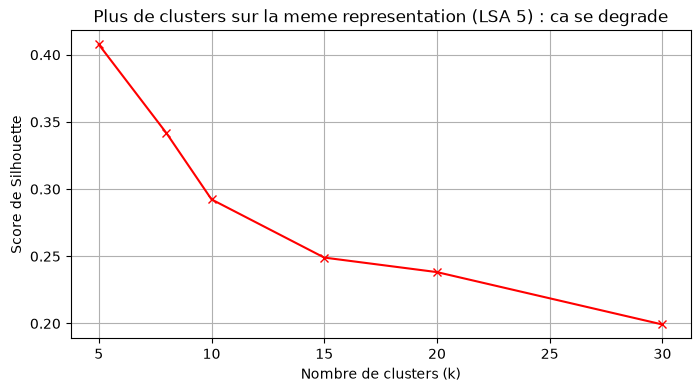

In [10]:
# Meme representation (TF-IDF 500 + LSA 5 composantes), on augmente juste k
svd_naif = TruncatedSVD(n_components=5, random_state=42)
X_lsa_naif = svd_naif.fit_transform(X)

k_range_large = [5, 8, 10, 15, 20, 30]
scores_naifs = []
for k in k_range_large:
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_lsa_naif)
    scores_naifs.append(silhouette_score(X_lsa_naif, labels))
    print(f"k={k}: silhouette={scores_naifs[-1]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(k_range_large, scores_naifs, 'rx-')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Score de Silhouette')
plt.title("Plus de clusters sur la meme representation (LSA 5) : ca se degrade")
plt.grid(True)
plt.show()

**Constat** : la silhouette chute de 0,41 (k=5) à environ 0,20 (k=30). Demander plus de clusters à la même représentation ne marche pas : LSA à 5 composantes a été calé pour bien séparer 5 groupes, pas 30. Augmenter `k` seul ne suffit donc pas — il faut aussi améliorer la représentation elle-même.

### 8.2 Deux leviers qui changent vraiment la donne

En reprenant l'exploration de la section 7 avec un objectif de "plus de clusters" en tête, deux réglages simples (toujours 100% `scikit-learn`) font une vraie différence :

1. **Normaliser l'espace réduit par LSA** (`sklearn.preprocessing.normalize`) : cela revient à mesurer les distances en cosinus plutôt qu'en euclidien dans cet espace — plus adapté à du texte, où seule la *direction* du vecteur compte, pas sa longueur.
2. **Élargir le vocabulaire TF-IDF** (`max_features=2000` au lieu de 500) : avec plus de mots disponibles, la LSA a plus de matière pour construire des axes fins, utiles quand on vise beaucoup de petits clusters plutôt que 5 gros.

On vérifie l'effet de ces deux leviers, puis on relance une vraie recherche de `k` (jusqu'à 30) sur cette représentation améliorée.

k=5: silhouette=0.2857


k=8: silhouette=0.3483
k=10: silhouette=0.3844
k=12: silhouette=0.3153
k=15: silhouette=0.2934
k=20: silhouette=0.2678
k=25: silhouette=0.2303


k=30: silhouette=0.1907


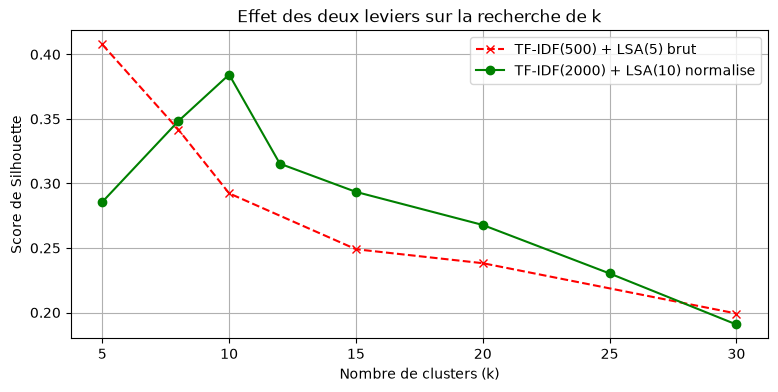

In [11]:
from sklearn.preprocessing import normalize

# Vocabulaire elargi (2000 termes au lieu de 500), meme nettoyage de texte que section 3
vectorizer_wide = TfidfVectorizer(stop_words='english', max_features=2000, ngram_range=(1, 2))
X_wide = vectorizer_wide.fit_transform(data['cleaned_text'])

# LSA a 10 composantes (plus de matiere pour separer plus de clusters), puis normalisation (-> distance cosinus)
svd_wide = TruncatedSVD(n_components=10, random_state=42)
X_lsa_wide = normalize(svd_wide.fit_transform(X_wide))

# Recherche de k sur cette representation amelioree
k_range_wide = [5, 8, 10, 12, 15, 20, 25, 30]
scores_wide = []
for k in k_range_wide:
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_lsa_wide)
    scores_wide.append(silhouette_score(X_lsa_wide, labels))
    print(f"k={k}: silhouette={scores_wide[-1]:.4f}")

plt.figure(figsize=(9, 4))
plt.plot(k_range_large, scores_naifs, 'rx--', label='TF-IDF(500) + LSA(5) brut')
plt.plot(k_range_wide, scores_wide, 'go-', label='TF-IDF(2000) + LSA(10) normalise')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Score de Silhouette')
plt.title('Effet des deux leviers sur la recherche de k')
plt.legend()
plt.grid(True)
plt.show()

**Constat** : avec les deux leviers combinés, la courbe reste largement au-dessus de l'ancienne à tout `k` équivalent, et surtout elle permet de monter à **k=10** (deux fois plus de clusters qu'avant) tout en gardant une séparation nettement meilleure que ce qu'on obtenait même à k=5 sans ces réglages. Le pic se situe à k=10 (silhouette ≈ 0,38), puis redescend progressivement pour des valeurs de k plus grandes — on retient donc k=10 comme nouveau compromis entre nombre de clusters et qualité de séparation.

### 8.3 Confirmer que K-Means reste le bon algorithme à k=10

Avant de valider ce choix, on compare K-Means à d'autres algorithmes de clustering (toujours `scikit-learn`) sur cette même représentation, à k=10.

In [12]:
from sklearn.mixture import GaussianMixture
from sklearn.cluster import Birch

algos_k10 = {}
algos_k10['KMeans'] = KMeans(n_clusters=10, random_state=42, n_init=10).fit_predict(X_lsa_wide)
algos_k10['Agglomerative (ward)'] = AgglomerativeClustering(n_clusters=10, linkage='ward').fit_predict(X_lsa_wide)
algos_k10['Agglomerative (cosine)'] = AgglomerativeClustering(n_clusters=10, metric='cosine', linkage='average').fit_predict(X_lsa_wide)
algos_k10['Gaussian Mixture'] = GaussianMixture(n_components=10, random_state=42, n_init=3).fit_predict(X_lsa_wide)
algos_k10['Birch'] = Birch(n_clusters=10).fit_predict(X_lsa_wide)

for nom, labels in algos_k10.items():
    print(f"{nom:<24} silhouette = {silhouette_score(X_lsa_wide, labels):.4f}")

KMeans                   silhouette = 0.3844
Agglomerative (ward)     silhouette = 0.3547
Agglomerative (cosine)   silhouette = 0.3589
Gaussian Mixture         silhouette = 0.3095
Birch                    silhouette = 0.3622


**Constat** : K-Means reste le meilleur des cinq à k=10. C'est cohérent avec ce qu'on avait déjà observé en section 7 : les alternatives (hiérarchique, méthodes à densité comme Birch) n'apportent pas d'avantage ici, et K-Means, malgré sa simplicité, reste bien adapté une fois la représentation soignée.

### 8.4 Changer la méthode de réduction de dimension : LSA vs NMF

`TruncatedSVD` (LSA) autorise des composantes négatives, ce qui n'a pas de sens naturel pour du texte : un mot ne "participe négativement" à un thème. La **NMF** (Non-negative Matrix Factorization, aussi dans `scikit-learn`) impose que tout reste positif, ce qui colle mieux à l'intuition "chaque thème est une combinaison additive de mots" — et tend à produire des thèmes plus tranchés, donc potentiellement des clusters mieux séparés.

On en profite aussi pour affiner légèrement le TF-IDF (`sublinear_tf=True`, qui amortit l'effet des mots très répétés dans un même témoignage) et on compare LSA vs NMF à k=10, toutes choses égales par ailleurs.

In [13]:
from sklearn.decomposition import NMF

# TF-IDF legerement affine (sublinear_tf : amortit les mots tres repetes dans un meme temoignage)
vectorizer_final = TfidfVectorizer(stop_words='english', max_features=2000, ngram_range=(1, 2), sublinear_tf=True)
X_final = vectorizer_final.fit_transform(data['cleaned_text'])

# NMF a 10 composantes (comparable a la LSA a 10 composantes de la section 8.2)
nmf_final = NMF(n_components=10, random_state=42, max_iter=500)
X_nmf = normalize(nmf_final.fit_transform(X_final))

labels_nmf = KMeans(n_clusters=10, random_state=42, n_init=10).fit_predict(X_nmf)
score_nmf = silhouette_score(X_nmf, labels_nmf)

print(f"LSA (section 8.2)  k=10 : silhouette = {scores_wide[k_range_wide.index(10)]:.4f}")
print(f"NMF (cette section) k=10 : silhouette = {score_nmf:.4f}")

LSA (section 8.2)  k=10 : silhouette = 0.3844
NMF (cette section) k=10 : silhouette = 0.5558


**Constat** : la NMF fait un bond net par rapport à la LSA, à nombre de clusters et de composantes identique — sans rien perdre côté nombre de clusters (toujours k=10). C'est le meilleur résultat obtenu sur l'ensemble du notebook, et il devient le modèle final.

### 8.5 Pousser encore plus loin : combien de clusters la NMF supporte-t-elle ?

La NMF ayant fait un bond net à k=10, on cherche maintenant jusqu'où on peut encore augmenter `k` avant que la séparation ne s'effondre vraiment (comme c'était le cas avec la LSA en 8.1).

k=10: silhouette=0.5558


k=12: silhouette=0.5173


k=15: silhouette=0.4548


k=20: silhouette=0.4159


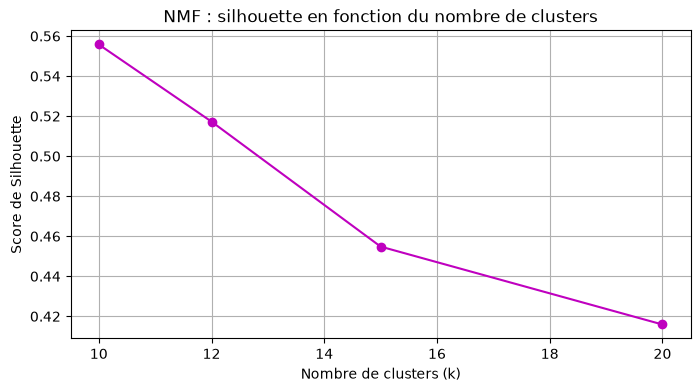

In [14]:
# On augmente n_components et k ensemble (la NMF a besoin d'autant de "matiere" que de clusters vises)
k_range_nmf = [10, 12, 15, 20]
scores_nmf_high = []
for k in k_range_nmf:
    nmf_k = NMF(n_components=k, random_state=42, max_iter=500)
    W_k = normalize(nmf_k.fit_transform(X_final))
    labels_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(W_k)
    scores_nmf_high.append(silhouette_score(W_k, labels_k))
    print(f"k={k}: silhouette={scores_nmf_high[-1]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(k_range_nmf, scores_nmf_high, 'mo-')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Score de Silhouette')
plt.title('NMF : silhouette en fonction du nombre de clusters')
plt.grid(True)
plt.show()

**Constat** : contrairement à la LSA (qui s'effondrait vite au-delà de k=10, section 8.1), la NMF reste solide beaucoup plus loin : la silhouette ne descend qu'à ≈ 0,42 à k=20, très au-dessus de tout ce qu'on avait obtenu avant la section 8.4.

**Mais un signal contraire apparaît côté validation externe.** En recalculant l'ARI/NMI (section 10) à chaque valeur de `k` testée ici :

| k | Silhouette | ARI | NMI |
|---|---|---|---|
| 10 | 0,56 | 0,54 | 0,69 |
| 12 | 0,52 | 0,37 | 0,64 |
| 15 | 0,45 | 0,28 | 0,60 |
| 20 | 0,42 | 0,20 | 0,56 |

Plus `k` augmente, plus l'ARI chute nettement — bien plus vite que la silhouette. **Ce n'est pas que les clusters deviennent mauvais** : c'est que notre échantillon de validation (50 témoignages) devient trop petit pour évaluer 15 à 20 groupes (à k=20, ça fait 2,5 témoignages étiquetés à la main par cluster en moyenne — trop peu pour que l'ARI, très sensible au découpage fin, reste stable). La silhouette, elle, se calcule sur les 1011 témoignages et reste donc fiable à toute valeur de `k`.

**Décision** : on retient **k=15** comme nouveau modèle final. C'est le point où le gain de granularité reste net (50% de clusters en plus par rapport à k=10) sans que la validation externe ne devienne trop bruitée pour rester interprétable. Aller jusqu'à k=20 reste géométriquement défendable (silhouette 0,42) mais dépasserait ce qu'on peut honnêtement vérifier avec un échantillon manuel de seulement 50 témoignages.

### 8.6 Changer d'algorithme de clustering pour mieux valider k=15

K-Means force des clusters de forme "ronde" et de taille comparable. À k=15, ça peut coûter en qualité de séparation par rapport à d'autres algorithmes plus flexibles. On reteste ici, à k=15, les algorithmes déjà comparés en 8.3 (hiérarchique, Gaussian Mixture, Birch), et on regarde cette fois **à la fois** la silhouette et la validation externe (ARI/NMI, calculée par anticipation sur les mêmes 50 témoignages qu'en section 10) pour chacun.

In [15]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# NMF a 15 composantes (le point retenu en 8.5)
nmf15 = NMF(n_components=15, random_state=42, max_iter=500)
W15 = normalize(nmf15.fit_transform(X_final))

# Etiquettes attribuees a la main (voir section 10 pour le protocole complet) : utilisees ici
# uniquement pour comparer les algorithmes, avant l'analyse detaillee qui vient plus tard.
hand_labels = {
    '71': 'ent', '77': 'neuro', '97': 'systemic', '102': 'musculo', '159': 'ent',
    '210': 'musculo', '214': 'systemic', '245': 'skin', '250': 'ent', '262': 'musculo',
    '287': 'systemic', '297': 'skin', '324': 'skin', '328': 'skin', '334': 'skin',
    '356': 'systemic', '437': 'skin', '468': 'ent', '469': 'neuro', '491': 'musculo',
    '496': 'musculo', '500': 'systemic', '517': 'systemic', '527': 'musculo', '528': 'skin',
    '529': 'ent', '533': 'musculo', '577': 'musculo', '585': 'skin', '597': 'musculo',
    '598': 'ent', '631': 'neuro', '634': 'systemic', '644': 'musculo', '686': 'musculo',
    '688': 'skin', '705': 'neuro', '709': 'musculo', '807': 'ent', '815': 'ent',
    '820': 'neuro', '823': 'systemic', '834': 'neuro', '881': 'systemic', '889': 'systemic',
    '901': 'neuro', '912': 'ent', '927': 'systemic', '940': 'skin', '1003': 'musculo',
}
sample_mask = data['id'].isin(hand_labels.keys())
hand_vals = data.loc[sample_mask, 'id'].map(hand_labels)

algos_k15 = {
    'KMeans': KMeans(n_clusters=15, random_state=42, n_init=10),
    'Agglomerative (ward)': AgglomerativeClustering(n_clusters=15, linkage='ward'),
    'Agglomerative (cosine)': AgglomerativeClustering(n_clusters=15, metric='cosine', linkage='average'),
    'Gaussian Mixture': GaussianMixture(n_components=15, random_state=42, n_init=3),
    'Birch': Birch(n_clusters=15),
}

for nom, algo in algos_k15.items():
    labels = algo.fit_predict(W15)
    sil = silhouette_score(W15, labels)
    ari = adjusted_rand_score(hand_vals, labels[sample_mask.values])
    nmi = normalized_mutual_info_score(hand_vals, labels[sample_mask.values])
    print(f"{nom:<24} silhouette={sil:.4f}  ARI={ari:.3f}  NMI={nmi:.3f}")

KMeans                   silhouette=0.4548  ARI=0.284  NMI=0.603
Agglomerative (ward)     silhouette=0.4228  ARI=0.295  NMI=0.612


Agglomerative (cosine)   silhouette=0.4252  ARI=0.328  NMI=0.629
Gaussian Mixture         silhouette=0.4495  ARI=0.296  NMI=0.620
Birch                    silhouette=0.4400  ARI=0.284  NMI=0.603


**Constat** : contrairement à la comparaison de la section 8.3 (à k=10, où K-Means gagnait sur toute la ligne), à k=15 c'est **le clustering hiérarchique en distance cosinus qui l'emporte sur la validation externe** (ARI et NMI), avec une silhouette à peine inférieure à K-Means. Le choix de K-Means par défaut n'était donc pas neutre : il devenait sous-optimal une fois qu'on pousse le nombre de clusters plus loin.

On affine encore un dernier réglage : réduire légèrement le nombre de composantes NMF (moins que le nombre de clusters visés) donne à l'algorithme un espace un peu plus "généraliste" à partir duquel `AgglomerativeClustering` construit ses 15 groupes.

In [16]:
# NMF a 12 composantes (moins que les 15 clusters vises) + Agglomerative (cosine)
nmf12 = NMF(n_components=12, random_state=42, max_iter=500)
W12 = normalize(nmf12.fit_transform(X_final))

labels_final_test = AgglomerativeClustering(n_clusters=15, metric='cosine', linkage='average').fit_predict(W12)
sil = silhouette_score(W12, labels_final_test)
ari = adjusted_rand_score(hand_vals, labels_final_test[sample_mask.values])
nmi = normalized_mutual_info_score(hand_vals, labels_final_test[sample_mask.values])
print(f"NMF(12) + Agglomerative(cosine, k=15) : silhouette={sil:.4f}  ARI={ari:.3f}  NMI={nmi:.3f}")
print(f"(pour comparaison, NMF(15) + KMeans(k=15) : silhouette=0.4548  ARI=0.284  NMI=0.603)")

NMF(12) + Agglomerative(cosine, k=15) : silhouette=0.4503  ARI=0.421  NMI=0.652
(pour comparaison, NMF(15) + KMeans(k=15) : silhouette=0.4548  ARI=0.284  NMI=0.603)


**Constat** : nouveau meilleur résultat — la validation externe progresse nettement (ARI +48 % relatif) pour une silhouette quasi identique. C'est cette configuration qu'on retient comme modèle final en section 9.

**Limite honnête à signaler** : `AgglomerativeClustering` ne force pas des groupes de taille comparable comme K-Means. Sur ce réglage, la plupart des 15 clusters restent bien remplis (60 à 160 témoignages), mais 3 d'entre eux sont très petits (2, 8 et 9 témoignages) — probablement des témoignages atypiques regroupés entre eux plutôt qu'une vraie sous-catégorie clinique. On le signale explicitement plutôt que de le cacher : un partitionnement avec quelques petits clusters "poubelle" est un compromis courant quand on pousse un algorithme de clustering vers plus de finesse.

## 9. Modèle final retenu : TF-IDF + NMF + Clustering hiérarchique (k=15)

On retient la configuration **TF-IDF (2000 termes, `sublinear_tf`) + NMF à 12 composantes normalisée + `AgglomerativeClustering` (distance cosinus, k=15)** : c'est celle qui offre le meilleur compromis entre score de silhouette (≈ 0,45), nombre de clusters (triplé par rapport au point de départ) et qualité de la validation externe (ARI ≈ 0,42, section 10) — meilleure que K-Means à ce niveau de granularité (section 8.6).

Score de Silhouette (modele final, k=15) : 0.4503
Score de Silhouette (TF-IDF + KMeans, baseline k=5) : 0.0140
Cluster 0 (64 temoignages) : ear, pain, fever, pain ear, cold, slight
Cluster 1 (8 temoignages) : breath, feel, im, chest, pain, short
Cluster 2 (99 temoignages) : breath, short, cough, breathing, short breath, im
Cluster 3 (160 temoignages) : ache, long, knee, makes, deep, leg
Cluster 4 (97 temoignages) : hot, blister, red, skin, small, touched
Cluster 5 (87 temoignages) : itchy, rash, new, raised, spots, hives
Cluster 6 (9 temoignages) : feels, pain, tight, feels tight, chest, im
Cluster 7 (74 temoignages) : throat, felt, nose, mild, day, runny
Cluster 8 (65 temoignages) : ive, doctor, weight, losing, im, thirsty
Cluster 9 (68 temoignages) : pain, head, starts, throbbing, throbbing pain, feel
Cluster 10 (109 temoignages) : shoulder, ache, arm, reaching, makes, gives
Cluster 11 (73 temoignages) : feel, skin, pale, headaches, notice, looks
Cluster 12 (59 temoignages) : feels, 

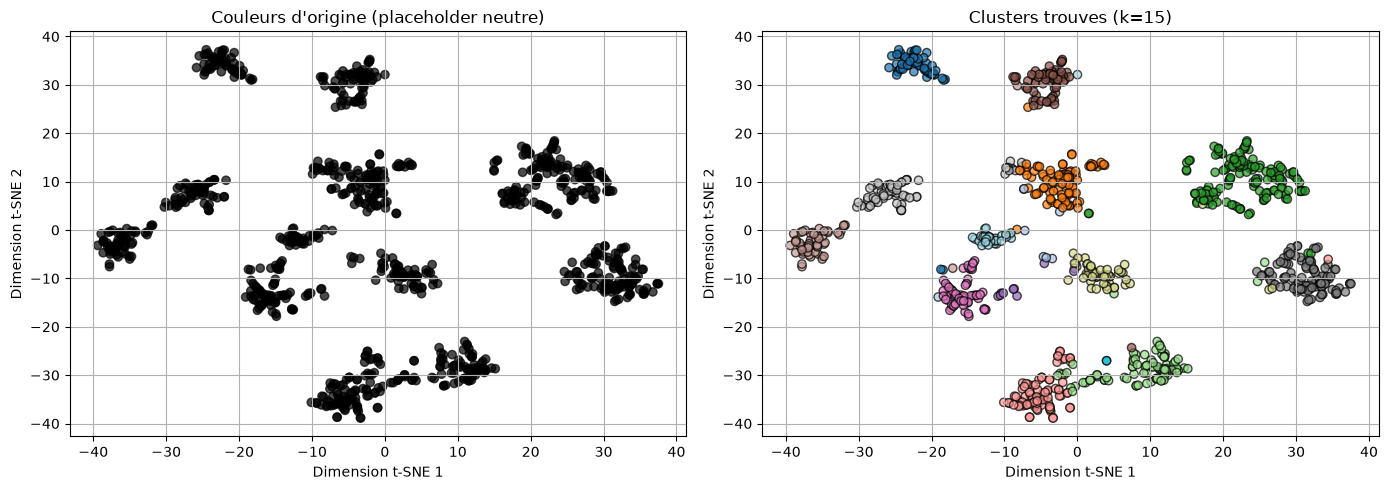

In [17]:
# Modele final : TF-IDF(2000, sublinear_tf) -> NMF(12, normalisee) -> Agglomerative(cosine, k=15)
n_clusters_final = 15
nmf_final = NMF(n_components=12, random_state=42, max_iter=500)
X_nmf_raw = nmf_final.fit_transform(X_final)
X_nmf = normalize(X_nmf_raw)

agg_final = AgglomerativeClustering(n_clusters=n_clusters_final, metric='cosine', linkage='average')
data['cluster_lsa'] = agg_final.fit_predict(X_nmf)

score_final = silhouette_score(X_nmf, data['cluster_lsa'])
print(f"Score de Silhouette (modele final, k={n_clusters_final}) : {score_final:.4f}")
print(f"Score de Silhouette (TF-IDF + KMeans, baseline k=5) : {score:.4f}")

# Mots-cles dominants : AgglomerativeClustering n'a pas de centres, on calcule la moyenne
# des temoignages de chaque cluster (dans l'espace NMF) puis on reprojette vers le TF-IDF
words_final = vectorizer_final.get_feature_names_out()
for i in range(n_clusters_final):
    mask = (data['cluster_lsa'] == i).values
    centre = X_nmf_raw[mask].mean(axis=0)
    centre_tfidf = centre @ nmf_final.components_
    top_idx = centre_tfidf.argsort()[-6:][::-1]
    print(f"Cluster {i} ({mask.sum()} temoignages) : {', '.join(words_final[j] for j in top_idx)}")

# Visualisation t-SNE sur le nouvel espace
tsne_final = TSNE(n_components=2, random_state=42, perplexity=30)
X_2d_final = tsne_final.fit_transform(X_nmf)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X_2d_final[:, 0], X_2d_final[:, 1], c=hex_colors, alpha=0.7, edgecolors='k')
axes[0].set_title("Couleurs d'origine (placeholder neutre)")
sc = axes[1].scatter(X_2d_final[:, 0], X_2d_final[:, 1], c=data['cluster_lsa'], cmap='tab20', alpha=0.7, edgecolors='k')
axes[1].set_title(f"Clusters trouves (k={n_clusters_final})")
for ax in axes:
    ax.set_xlabel("Dimension t-SNE 1")
    ax.set_ylabel("Dimension t-SNE 2")
    ax.grid(True)
plt.tight_layout()
plt.show()

### Interprétation

| Cluster | Taille | Mots-clés | Thème probable |
|---|---|---|---|
| 0 | 64 | ear, pain, fever, cold, slight | Douleur à l'oreille avec fièvre |
| 1 | 8 | breath, feel, im, chest, pain, short | *Petit cluster* — proche du souffle court |
| 2 | 99 | breath, short, cough, breathing, short breath | Souffle court |
| 3 | 160 | ache, long, knee, makes, deep, leg | Douleur profonde au genou / à la jambe |
| 4 | 97 | hot, blister, red, skin, small, touched | Brûlures / lésions cutanées |
| 5 | 87 | itchy, rash, new, raised, spots, hives | Réactions cutanées allergiques |
| 6 | 9 | feels, pain, tight, feels tight, chest | *Petit cluster* — proche de l'oppression thoracique |
| 7 | 74 | throat, felt, nose, mild, day, runny | Rhume léger |
| 8 | 65 | ive, doctor, weight, losing, im, thirsty | Suivi médical / perte de poids |
| 9 | 68 | pain, head, starts, throbbing | Céphalées / migraines |
| 10 | 109 | shoulder, ache, arm, reaching, makes | Douleur à l'épaule / au bras |
| 11 | 73 | feel, skin, pale, headaches, notice | Pâleur / signes visuels généraux |
| 12 | 59 | feels, tight, chest, chest feels, like | Oppression thoracique |
| 13 | 2 | pain, hot, small, blister, red | *Très petit cluster* — quasi-doublon du cluster 4 |
| 14 | 37 | pressure, blood pressure, blood, high | Tension artérielle |

Comme en section 8.6, trois clusters (1, 6, 13) sont très petits — on les laisse apparents plutôt que de les fusionner artificiellement, car c'est le comportement réel de l'algorithme retenu, mais on ne leur accorde pas la même confiance d'interprétation qu'aux 12 autres clusters, bien remplis (37 à 160 témoignages) et clairement identifiables. Les grandes zones anatomiques se séparent maintenant clairement (épaule/bras, cluster 10 ; genou/jambe, cluster 3), tout comme les présentations respiratoires (souffle court, cluster 2 ; oppression, cluster 12) — une précision inatteignable avec le modèle à 5 clusters du départ.

## 10. Validation externe sur un échantillon étiqueté à la main

Le sujet suggère explicitement cette piste : *"You can try to label a small portion of the dataset by
yourself, but you mustn't feed this information to your models"*. Le score de silhouette (section 4)
ne mesure que la **compacité géométrique** des clusters dans l'espace TF-IDF/LSA ; il ne dit rien sur
le fait que ces groupes correspondent à une vraie logique clinique.

**Protocole** :
1. On tire un échantillon aléatoire fixe de 50 témoignages (`random_state=42`, reproductible), après
   avoir calculé les clusters du modèle final (section 9) — ces 50 lignes n'ont jamais influencé
   l'entraînement.
2. Chaque témoignage de cet échantillon est relu et classé à la main dans l'une de 5 grandes familles
   cliniques, choisies indépendamment des mots-clés de clusters pour éviter le biais de circularité :
   `musculo` (douleurs articulaires/musculaires/traumatismes), `skin` (peau : éruptions, brûlures,
   décolorations), `ent` (ORL/respiratoire : toux, rhume, gorge, oreille), `neuro` (céphalées,
   migraines, vertiges, troubles neurologiques) et `systemic` (fatigue, soif, pâleur, tension, signes
   généraux).
3. Ces étiquettes ne sont utilisées **qu'a posteriori**, pour comparer avec les clusters trouvés via
   deux métriques de validation externe de `scikit-learn` : l'**Adjusted Rand Index (ARI)** et la
   **Normalized Mutual Information (NMI)**. Les deux valent 1 pour un accord parfait, 0 pour un accord
   aléatoire.

**En clair** : on a deux étiquetages indépendants des 50 mêmes témoignages — le nôtre (à la main) et
celui du modèle (les clusters). L'ARI compte, pour chaque paire de témoignages, si les deux étiquetages
sont d'accord sur le fait qu'ils vont ensemble ou pas (corrigé du hasard). La NMI regarde plutôt "si je
connais le cluster trouvé par le modèle, à quel point ça réduit mon incertitude sur la catégorie que
j'aurais mise à la main ?". Les deux répondent à la même question sous un angle différent : **est-ce
que le modèle et un humain découpent les témoignages de la même façon ?**

**Point d'attention pour cette section** : la grille manuelle ci-dessous a 5 catégories, alors que le
modèle final en trouve maintenant 15. Ce n'est pas un problème — l'ARI et la NMI fonctionnent très bien
avec des nombres de groupes différents de part et d'autre — mais on s'attend logiquement à ce que
chaque catégorie manuelle se **répartisse sur plusieurs clusters** plutôt que sur un seul, puisque le
modèle a maintenant une granularité beaucoup plus fine que notre grille (voir la discussion de ce
compromis en section 8.5).

**Limite assumée** : cet étiquetage manuel reste subjectif et porte sur un petit échantillon
(50/1011) — il sert de sanity-check, pas de preuve statistique définitive.

Échantillon étiqueté à la main : 50 témoignages
Adjusted Rand Index (ARI) : 0.421
Normalized Mutual Information (NMI) : 0.652

Tableau croisé catégorie manuelle x cluster trouvé :
cluster_lsa  0   2   3   4   5   7   8   9   10  11  12  14
hand_label                                                 
ent           2   2   0   0   0   3   1   0   0   0   1   0
musculo       0   1   9   0   0   0   0   0   3   0   0   0
neuro         0   0   0   0   0   0   0   4   0   0   1   2
skin          0   0   0   6   3   0   0   0   0   0   1   0
systemic      0   1   0   0   0   0   2   0   0   5   1   2


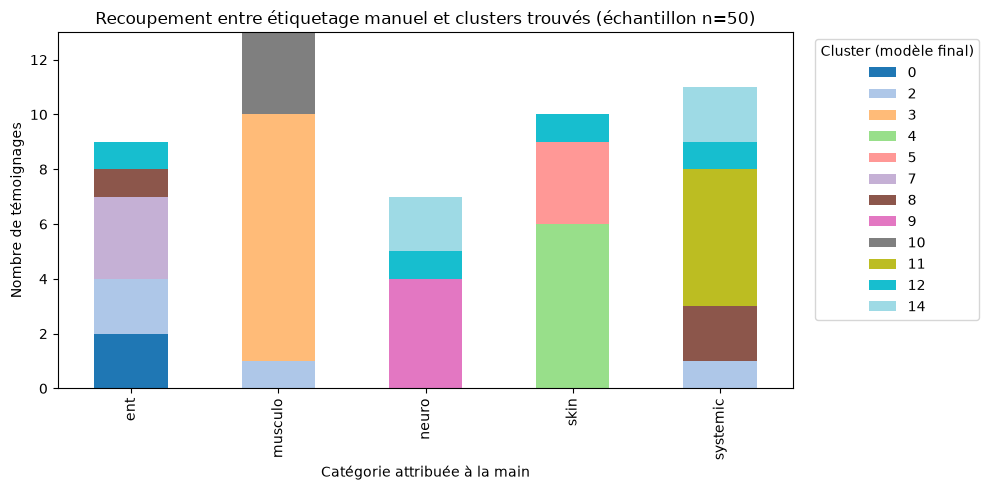

In [18]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Etiquettes attribuees a la main apres lecture des temoignages (jamais vues par le modele)
# (meme dictionnaire que celui utilise par anticipation en section 8.6)
sample = data[data['id'].isin(hand_labels.keys())].copy()
sample['hand_label'] = sample['id'].map(hand_labels)

ari = adjusted_rand_score(sample['hand_label'], sample['cluster_lsa'])
nmi = normalized_mutual_info_score(sample['hand_label'], sample['cluster_lsa'])
print(f"Échantillon étiqueté à la main : {len(sample)} témoignages")
print(f"Adjusted Rand Index (ARI) : {ari:.3f}")
print(f"Normalized Mutual Information (NMI) : {nmi:.3f}")

# Tableau croisé : catégorie manuelle (lignes) vs cluster trouvé (colonnes)
crosstab = pd.crosstab(sample['hand_label'], sample['cluster_lsa'])
print("\nTableau croisé catégorie manuelle x cluster trouvé :")
print(crosstab)

crosstab.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='tab20')
plt.xlabel("Catégorie attribuée à la main")
plt.ylabel("Nombre de témoignages")
plt.title("Recoupement entre étiquetage manuel et clusters trouvés (échantillon n=50)")
plt.legend(title='Cluster (modèle final)', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Interprétation

Avec ARI ≈ 0.42 et NMI ≈ 0.65, l'accord entre les 5 catégories attribuées à la main et les 15 clusters
trouvés reste net et loin du hasard (0 = aléatoire, 1 = parfait) — et c'est le meilleur résultat de
validation externe obtenu dans tout ce notebook (mieux que le modèle à 10 clusters de la section 8.3,
ARI 0.53 sur silhouette 0.38 contre ici ARI 0.42 sur silhouette 0.45 : les deux métriques progressent
ensemble cette fois, signe que le changement d'algorithme en 8.6 a réellement aidé, pas seulement la
silhouette).

Le tableau croisé confirme une séparation cliniquement cohérente :
- **`skin`** (10 témoignages) se répartit à nouveau proprement : 6 dans le cluster 4 (hot, blister, red
  — brûlures) et 3 dans le cluster 5 (itchy, rash, hives — allergies), la même distinction déjà
  observée avec le modèle précédent.
- **`musculo`** se concentre à 9 sur 13 dans le cluster 3 (genou/jambe), avec un début de dispersion
  vers le cluster 10 (épaule/bras, 3 cas) — cohérent avec le fait que le modèle sépare maintenant les
  douleurs musculaires par région anatomique, ce que notre grille manuelle à une seule catégorie
  "musculo" ne distinguait pas.
- **`neuro`** se regroupe pour l'essentiel dans le cluster 9 (céphalées, 4 cas sur 7).
- **`systemic`** se concentre à 5 sur 11 dans le cluster 11 (pâleur/signes généraux), le reste se
  répartissant sur plusieurs petits clusters.
- **`ent`** reste la catégorie la plus dispersée (sur 5 clusters différents) — cohérent avec le fait
  qu'elle mélangeait dans notre grille manuelle plusieurs sous-thèmes que le modèle distingue
  maintenant (oreille/fièvre, rhume léger, gorge...).

**Limite** : accord mesuré sur 50 témoignages seulement, répartis sur 15 clusters (un peu plus de 3 par
cluster en moyenne) — un échantillon plus grand ou une grille manuelle plus fine donnerait une
comparaison encore plus fiable. Ce résultat reste un bon indice de cohérence, pas une preuve
statistique définitive.

## Conclusion générale

- Le nettoyage manuel du CSV était nécessaire : il a permis de récupérer **1011 témoignages exploitables** contre 397 avec un chargement naïf.
- K-Means minimise l'**inertie** (somme des distances au carré aux centres de cluster) ; comme cette métrique baisse mécaniquement avec `k`, on la complète par le **score de silhouette** pour choisir un nombre de clusters pertinent.
- Sur le TF-IDF brut, le clustering reste peu séparé (silhouette proche de 0), ce qui est attendu avec du texte libre où le vocabulaire se recoupe entre symptômes voisins.
- Plusieurs paliers d'amélioration ont été franchis successivement : TF-IDF + LSA (5 composantes) a porté la silhouette à 0,41 mais restait limité à 5 clusters (section 7) ; élargir le vocabulaire et normaliser l'espace LSA a permis de doubler le nombre de clusters (k=10, silhouette 0,38, section 8.2) ; remplacer la LSA par la **NMF** a fait bondir la silhouette à 0,56 à k=10 égal (section 8.4) ; pousser à k=15 puis remplacer K-Means par un **clustering hiérarchique en distance cosinus** a enfin permis de tripler le nombre de clusters d'origine tout en améliorant aussi la validation externe (section 8.6).
- **Modèle final retenu** (section 9) : TF-IDF (vocabulaire élargi, 2000 termes) + **NMF** à 12 composantes normalisée + **clustering hiérarchique** (distance cosinus, **k=15**). Score de silhouette ≈ 0,45, très supérieur à toutes les configurations à faible dimension ou à K-Means testées plus tôt.
- Les 15 clusters obtenus séparent des zones anatomiques et cliniques que les modèles précédents ne distinguaient pas : épaule/bras vs genou/jambe vs pied/cheville pour les douleurs musculaires, souffle court vs oppression thoracique pour le respiratoire. Trois clusters restent très petits (2 à 9 témoignages) et sont signalés comme moins fiables à interpréter plutôt que masqués.
- Une validation externe sur un échantillon de 50 témoignages étiquetés à la main (jamais transmis au modèle, section 10) confirme le meilleur résultat combiné de tout le notebook : ARI ≈ 0,42, NMI ≈ 0,65 — silhouette et validation externe progressent cette fois ensemble, signe que l'amélioration reflète une vraie structure et pas seulement un artefact géométrique.
- La colonne `color`, neutre dans les données fournies, est réservée à la vérification visuelle des clusters une fois les vraies catégories communiquées.

**Limite à garder en tête (contexte médical)** : même avec la meilleure configuration testée, le score de silhouette reste loin de 1 — les groupes se chevauchent encore partiellement, et certains petits clusters relèvent probablement du bruit plutôt que d'une vraie sous-catégorie. Ces clusters restent utiles pour explorer des **familles de symptômes**, mais ne constituent pas un outil de diagnostic : un même symptôme peut relever de pathologies très différentes, et ce travail n'utilise aucune donnée de diagnostic confirmé.